<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/Padv_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
data = {
    "Hours_Studied": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                      2, 4, 6, 8, 3, 5, 7, 9, 1, 10],
    "Attendance": [40, 45, 50, 55, 60, 65, 70, 80, 90, 95,
                   48, 58, 68, 85, 52, 62, 75, 92, 42, 98],
    "Result": ["Fail", "Fail", "Fail", "Fail", "Pass",
               "Pass", "Pass", "Pass", "Pass", "Pass",
               "Fail", "Fail", "Pass", "Pass", "Fail",
               "Pass", "Pass", "Pass", "Fail", "Pass"]
}


In [3]:
df = pd.DataFrame(data)

In [5]:
# Define features and target
X = df[['Hours_Studied', 'Attendance']]
y = df['Result']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and fit the model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [6]:
y_pred = model.predict(X_test)

In [7]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"]))

Confusion Matrix:
[[2 0]
 [0 4]]


In [8]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



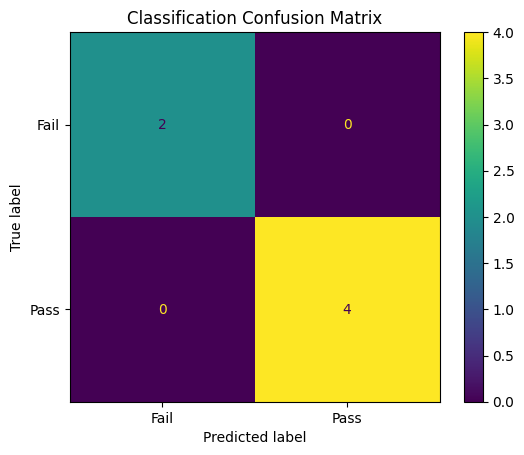

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["Fail", "Pass"]
)
plt.title("Classification Confusion Matrix")
plt.show()

In [11]:
columns = ["Hours_Studied", "Attendance"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))

    print("Outlier Values:")
    print(outliers[col].tolist())


Column: Hours_Studied
Q1: 3.0
Q3: 8.0
IQR: 5.0
Lower Bound: -4.5
Upper Bound: 15.5
Number of Outliers: 0
Outlier Values:
[]

Column: Attendance
Q1: 51.5
Q3: 81.25
IQR: 29.75
Lower Bound: 6.875
Upper Bound: 125.875
Number of Outliers: 0
Outlier Values:
[]
